# Atlanta Mall Distance: Controlled Nonlinearity and Robustness

24 ZCTAs; 2024 ACS5; 30322 excluded. Income n=23, Gini n=24. Results are descriptive, not causal.

Run all cells. Requires pandas, numpy, statsmodels, matplotlib.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, statsmodels.formula.api as smf, statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
BASE=Path.cwd()
if not (BASE/"analysis_data.csv").exists():
    matches=list((Path.home()/"Downloads").rglob("analysis_data.csv"))
    if not matches: raise FileNotFoundError("Open the extracted Atlanta_Robustness_Study folder in VS Code, or locate analysis_data.csv in Downloads")
    BASE=matches[0].parent
d=pd.read_csv(BASE/"analysis_data.csv",dtype={"ZCTA":str})
print("ZCTAs:",d.ZCTA.nunique(),"rows:",len(d))

ZCTAs: 24 rows: 72


## Model comparison: separate mall regressions
HC3 heteroskedasticity-robust inference; dependent variables log median household income and Gini.

In [2]:
comparison=pd.read_csv(BASE/"model_comparison.csv")
display(comparison.round(4))

,mall,outcome,model,n,r2,adj_r2,aic,coef_distance,p_distance,coef_quadratic,p_quadratic
0,Lenox Square,log_income,linear,23,0.3289,0.2970,13.5143,-0.0532,0.0143,NaN,NaN
1,Lenox Square,log_income,quadratic,23,0.3337,0.2671,15.3494,-0.0303,0.7017,-0.0014,0.8160
2,Lenox Square,log_income,controlled_linear,23,0.9467,0.9348,-38.7318,0.0174,0.0248,NaN,NaN
3,Lenox Square,log_income,controlled_quadratic,23,0.9471,0.9316,-36.9329,0.0247,0.4979,-0.0005,0.8282
4,Lenox Square,gini,linear,24,0.0428,-0.0007,-96.3274,0.0016,0.4374,NaN,NaN
5,Lenox Square,gini,quadratic,24,0.0639,-0.0253,-94.8612,-0.0024,0.7696,0.0002,0.6763
6,Lenox Square,gini,controlled_linear,24,0.5118,0.4091,-106.4882,-0.0004,0.8705,NaN,NaN
7,Lenox Square,gini,controlled_quadratic,24,0.6049,0.4951,-109.5637,-0.0090,0.1644,0.0005,0.3330
8,Phipps Plaza,log_income,linear,23,0.3192,0.2867,13.8474,-0.0472,0.0105,NaN,NaN
9,Phipps Plaza,log_income,quadratic,23,0.3194,0.2513,15.8409,-0.0428,0.5092,-0.0003,0.9531


## Mall-type interaction
Pooled mall-ZCTA observations share ZIP-level outcomes. Standard errors clustered by ZIP. Mall fixed effects included. Two Buckhead destinations are not independent mall-type replications.

In [3]:
display(pd.read_csv(BASE/"mall_type_interactions.csv").round(4))

,outcome,model,n,n_zip,coef_interaction,p_interaction,coef_distance,p_distance,r2
0,log_income,interaction,69,23,0.0506,0.1115,-0.0499,0.0041,0.2153
1,log_income,controlled_interaction,69,23,-0.0073,0.3302,0.0108,0.0405,0.9373
2,gini,interaction,72,24,-0.0001,0.9617,0.0013,0.4556,0.0223
3,gini,controlled_interaction,72,24,0.0005,0.7831,-0.0004,0.7957,0.5117


## Leave-one-ZIP-out sensitivity and multicollinearity

In [4]:
display(pd.read_csv(BASE/"leave_one_zip_out.csv").round(4))
display(pd.read_csv(BASE/"vif_diagnostics.csv").round(2))

,mall,outcome,model,n,min_coef,max_coef,sign_flip,share_p_below_05
0,Lenox Square,log_income,controlled_linear,23,0.0135,0.0212,False,0.7826
1,Lenox Square,log_income,controlled_quadratic,23,0.0145,0.0548,False,0.0000
2,Lenox Square,gini,controlled_linear,24,-0.0018,0.0004,True,0.0000
3,Lenox Square,gini,controlled_quadratic,24,-0.0131,-0.0059,False,0.0417
4,Phipps Plaza,log_income,controlled_linear,23,0.0086,0.0165,False,0.0870
5,Phipps Plaza,log_income,controlled_quadratic,23,0.0090,0.0533,False,0.0000
6,Phipps Plaza,gini,controlled_linear,24,-0.0019,0.0001,True,0.0000
7,Phipps Plaza,gini,controlled_quadratic,24,-0.0108,-0.0046,False,0.0000
8,Ponce City Market,log_income,controlled_linear,23,-0.0025,0.0053,True,0.0000
9,Ponce City Market,log_income,controlled_quadratic,23,-0.0622,-0.0104,False,0.0000


,mall,outcome,variable,vif
0,Lenox Square,log_income,driving_miles,15.28
1,Lenox Square,log_income,distance2,15.17
2,Lenox Square,log_income,education_share,6.52
3,Lenox Square,log_income,poverty_rate,5.74
4,Lenox Square,log_income,home_value_100k,2.50
5,Lenox Square,gini,driving_miles,14.84
6,Lenox Square,gini,distance2,14.92
7,Lenox Square,gini,education_share,6.61
8,Lenox Square,gini,poverty_rate,3.97
9,Lenox Square,gini,home_value_100k,2.27


## Visualize controlled linear vs quadratic income relationships
Other covariates held at their sample means; interpret as conditional model predictions, not causal effects.

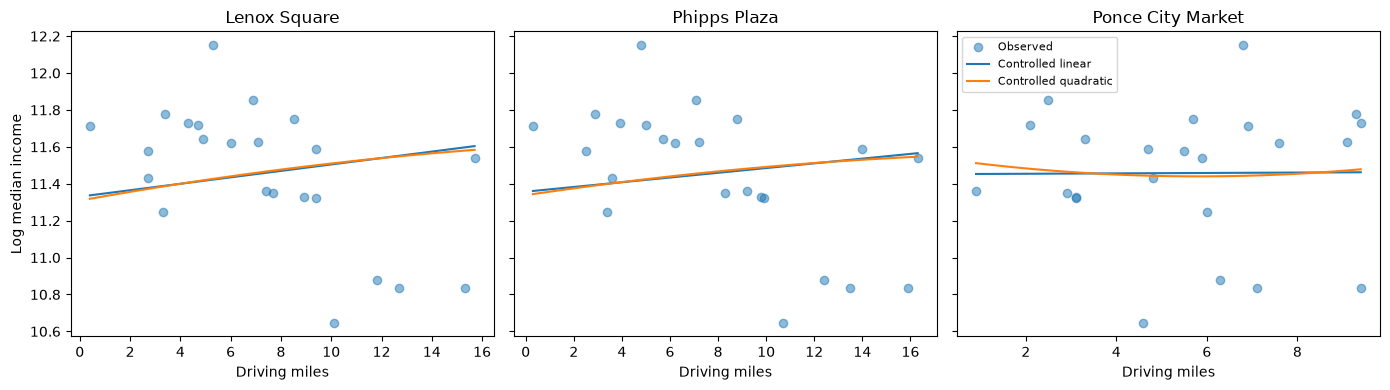

In [5]:
import matplotlib.pyplot as plt
fig,axs=plt.subplots(1,3,figsize=(14,4),sharey=True)
for ax,(mall,g) in zip(axs,d.groupby("Destination")):
 g=g.dropna(subset=["log_income","education_share","poverty_rate","home_value_100k"])
 f1=smf.ols("log_income ~ driving_miles + education_share + poverty_rate + home_value_100k",g).fit()
 f2=smf.ols("log_income ~ driving_miles + distance2 + education_share + poverty_rate + home_value_100k",g).fit()
 x=np.linspace(g.driving_miles.min(),g.driving_miles.max(),100)
 pred=pd.DataFrame({"driving_miles":x,"distance2":x*x,**{c:g[c].mean() for c in ["education_share","poverty_rate","home_value_100k"]}})
 ax.scatter(g.driving_miles,g.log_income,alpha=.5,label="Observed")
 ax.plot(x,f1.predict(pred),label="Controlled linear")
 ax.plot(x,f2.predict(pred),label="Controlled quadratic")
 ax.set(title=mall,xlabel="Driving miles")
axs[0].set_ylabel("Log median income")
axs[-1].legend(fontsize=8)
plt.tight_layout();plt.show()

## Limitations
Only 24 ZIPs (23 for income). Quadratic terms may be collinear with distance; center distance before fitting if interpreting coefficients. Education, poverty, home value are potentially jointly determined with income. The three destinations share the same ZIP outcomes; 2 Buckhead malls are not independent treatment replications. Cross-sectional patterns do not identify an economic impact radius or redevelopment effect.